# Previsão diária de bicicletas

A pergunta é simples: usando apenas o histórico até certa data, quão bem conseguimos prever os dias seguintes? O código do experimento está em [forecast.py](forecast.py). Aqui mostro a divisão dos dados, a escolha do modelo e onde ele erra.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from forecast import DATA_URL, preparar_dados, dividir, experimento

serie, dias_excluidos = preparar_dados(pd.read_csv(DATA_URL))
desenvolvimento, validacao, treino, teste = dividir(serie)
print(f"{len(serie)} dias completos; {dias_excluidos} incompletos fora da modelagem")
display(pd.DataFrame({
    "parte": ["Desenvolvimento", "Validação", "Teste reservado"],
    "dias": [len(desenvolvimento), len(validacao), len(teste)],
    "início": [x.ds.min().date() for x in (desenvolvimento, validacao, teste)],
    "fim": [x.ds.max().date() for x in (desenvolvimento, validacao, teste)],
}))

696 dias completos; 34 incompletos fora da modelagem


,parte,dias,início,fim
0,Desenvolvimento,466,2015-01-04,2016-05-07
1,Validação,90,2016-05-08,2016-08-09
2,Teste reservado,140,2016-08-10,2017-01-03


Importing plotly failed. Interactive plots will not work.


## Regra de comparação

O teste são os 20% finais dos dias completos. Separo os últimos 90 dias do trecho anterior para escolher o método. A referência reaproveita, para cada dia da semana, o último valor desse dia visto no treino; é uma previsão fixa para todo o horizonte, sem consultar valores futuros.

As outras opções são Prophet padrão, Prophet com sazonalidade anual e a mesma configuração após remover observações fora do intervalo ajustado **somente no treino**. A menor RMSE na validação decide o modelo. Remover picos não é automaticamente uma melhoria: eles podem ser demanda legítima.

In [4]:
validacao_modelos, final = experimento(serie)
display(validacao_modelos.round(2))
print("Escolhido pela validação:", final["modelo"])

Escolhido pela validação: prophet_anual


,modelo,RMSE,MAE,outliers_removidos_no_ajuste
0,prophet_anual,6605.41,5199.87,0
1,prophet_anual_sem_outliers,6609.79,5128.42,54
2,prophet_padrao,6992.02,5798.12,0
3,ultimo_dia_semana,9549.77,7544.33,0


10:17:42 - cmdstanpy - INFO - Chain [1] start processing
10:17:42 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
10:17:42 - cmdstanpy - INFO - Chain [1] start processing
10:17:42 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
10:17:42 - cmdstanpy - INFO - Chain [1] start processing
10:17:42 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of hi

## Teste reservado

Depois de escolher o método, ele é ajustado novamente com todo o trecho anterior ao teste. A referência semanal também é avaliada no mesmo período para dar escala ao erro; ela não foi usada para ajustar o resultado do modelo escolhido.

,modelo,RMSE,MAE
0,prophet_anual,6160.98,4937.92
1,referência semanal,13849.16,11049.48


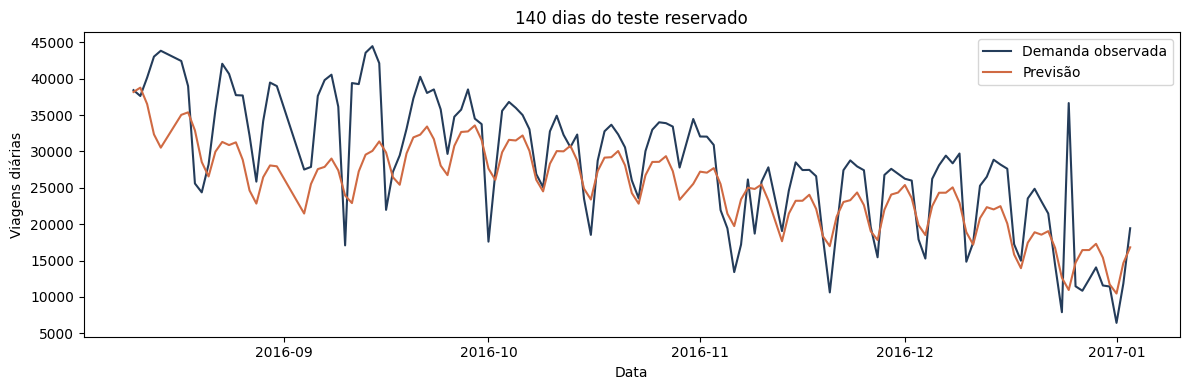

In [6]:
comparacao = pd.DataFrame([
    {"modelo": final["modelo"], **final["teste"]},
    {"modelo": "referência semanal", **final["referencia_teste"]},
])
display(comparacao.round(2))
previsoes = final["previsoes"].copy()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(previsoes["ds"], previsoes["y"], label="Demanda observada", color="#243c5a")
ax.plot(previsoes["ds"], previsoes["yhat"], label="Previsão", color="#d06a43")
ax.set(title="140 dias do teste reservado", xlabel="Data", ylabel="Viagens diárias")
ax.legend()
fig.tight_layout()
plt.show()

## Olhando os erros, não só a média

O RMSE de 6.160,98 viagens por dia é menor que os 13.849,16 da referência no teste, mas o gráfico mostra picos que o modelo subestima. A tabela abaixo ajuda a localizar os maiores desvios antes de pensar em outras variáveis ou ajustes.

In [8]:
previsoes["erro"] = previsoes["y"] - previsoes["yhat"]
previsoes["erro_absoluto"] = previsoes["erro"].abs()
display(previsoes.nlargest(5, "erro_absoluto")[["ds", "y", "yhat", "erro"]].round(1))
print("Erro médio por dia da semana (positivo = subestimação):")
display(previsoes.groupby(previsoes["ds"].dt.day_name())["erro"].mean().round(0).sort_values(ascending=False))

Erro médio por dia da semana (positivo = subestimação):


,ds,y,yhat,erro
686,2016-12-25,36653,10945.0,25708.0
583,2016-09-11,39403,22896.9,16506.1
586,2016-09-14,44478,30075.1,14402.9
585,2016-09-13,43573,29558.3,14014.7
560,2016-08-14,43848,30519.2,13328.8


ds
Wednesday    5182.0
Tuesday      5147.0
Monday       3358.0
Thursday     3293.0
Friday       2552.0
Sunday       2549.0
Saturday      -10.0
Name: erro, dtype: float64

## O que ainda falta

Este é um único recorte de validação e um único teste. O Prophet anual foi ajustado com menos de dois anos de histórico, condição em que a sazonalidade pode ser instável. Dias incompletos foram excluídos e isso pode mudar a amostra. Para avaliar a consistência do método, o próximo passo seria repetir a previsão a partir de várias datas de corte e, se possível, usar mais anos de dados, como nos [diagnósticos do Prophet](https://facebook.github.io/prophet/docs/diagnostics.html).